### Bài 1: Xây dựng mô hình 1-layer MLP và hàm Softmax làm activation function. Huấn luyện mô hình này sử dụng SGD làm optimizer và đánh giá trên các độ đo accuracy, precision, recall và F1-macro. Đánh giá kết quả của mô hình với từng chữ số.



100%|██████████| 9.91M/9.91M [01:32<00:00, 108kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 95.0kB/s]
100%|██████████| 1.65M/1.65M [01:08<00:00, 24.0kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.57MB/s]


device: cpu
train / val / test: 54000 6000 10000
Số tham số: 7850
epoch  1 | train_loss 0.3769 | val_loss 0.3477 | val_acc 0.9025 | 16.5s
epoch  2 | train_loss 0.3117 | val_loss 0.3475 | val_acc 0.9005 | 16.3s
epoch  3 | train_loss 0.3014 | val_loss 0.3261 | val_acc 0.9087 | 16.0s
epoch  4 | train_loss 0.2943 | val_loss 0.3266 | val_acc 0.9115 | 16.3s
epoch  5 | train_loss 0.2901 | val_loss 0.3333 | val_acc 0.9072 | 16.3s
epoch  6 | train_loss 0.2857 | val_loss 0.3526 | val_acc 0.9035 | 16.5s
epoch  7 | train_loss 0.2825 | val_loss 0.3375 | val_acc 0.9067 | 16.1s
epoch  8 | train_loss 0.2820 | val_loss 0.3339 | val_acc 0.9113 | 16.1s
epoch  9 | train_loss 0.2799 | val_loss 0.3359 | val_acc 0.9120 | 16.5s
epoch 10 | train_loss 0.2778 | val_loss 0.3420 | val_acc 0.9023 | 16.8s
epoch 11 | train_loss 0.2767 | val_loss 0.3362 | val_acc 0.9128 | 16.2s
epoch 12 | train_loss 0.2749 | val_loss 0.3352 | val_acc 0.9115 | 16.0s
epoch 13 | train_loss 0.2740 | val_loss 0.3649 | val_acc 0.9033 | 16.5

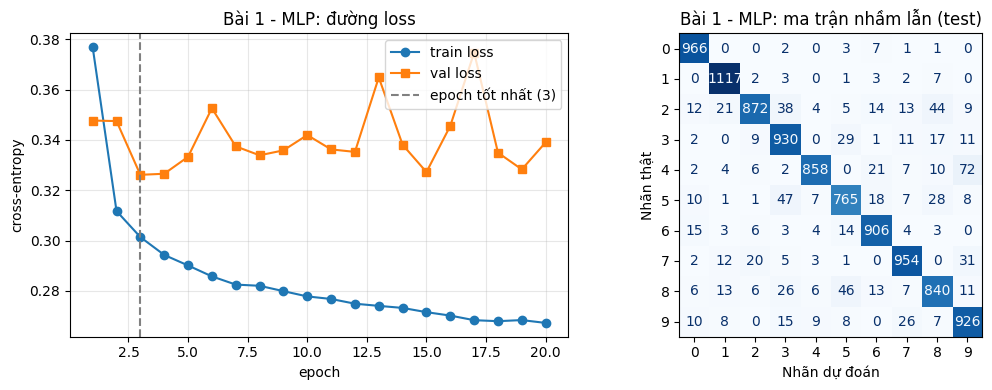

=== Bài 1 - MLP | số tham số: 7,850 ===
Accuracy             0.9134
Precision (macro)    0.9135
Recall (macro)       0.9121
F1 (macro)           0.9120

Đánh giá từng chữ số:
        Precision  Recall      F1  Support
Chữ số                                    
0          0.9424  0.9857  0.9636      980
1          0.9474  0.9841  0.9654     1135
2          0.9458  0.8450  0.8925     1032
3          0.8683  0.9208  0.8938     1010
4          0.9630  0.8737  0.9162      982
5          0.8773  0.8576  0.8673      892
6          0.9217  0.9457  0.9335      958
7          0.9244  0.9280  0.9262     1028
8          0.8777  0.8624  0.8700      974
9          0.8670  0.9177  0.8917     1009

Chữ số khó nhất: 5 (F1 = 0.8673)
3 cặp (thật -> đoán) nhầm nhiều nhất:
  4 -> 9: 72 ảnh
  5 -> 3: 47 ảnh
  8 -> 5: 46 ảnh


In [1]:
import pandas as pd
import random
import time, copy
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)


def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"


tf = transforms.Compose([                          # [0,255] -> [0,1]
    transforms.ToTensor(),                         # mean/std của MNIST
    transforms.Normalize((0.1307,), (0.3081,)),
])
train_full = datasets.MNIST("data", train=True,  download=True, transform=tf)
test_ds    = datasets.MNIST("data", train=False, download=True, transform=tf)


g = torch.Generator().manual_seed(42)
train_ds, val_ds = random_split(train_full, [54000, 6000], generator=g)

BATCH = 64
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,
                          generator=torch.Generator().manual_seed(42))
val_loader   = DataLoader(val_ds,  batch_size=256)
test_loader  = DataLoader(test_ds, batch_size=256)

print("device:", device)
print("train / val / test:", len(train_ds), len(val_ds), len(test_ds))


def count_params(model):
    return sum(p.numel() for p in model.parameters())

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()               # 1. xoá gradient cũ
        loss = criterion(model(x), y)       # 2. forward + tính loss
        loss.backward()                     # 3. tính gradient
        optimizer.step()                    # 4. cập nhật trọng số
        total += loss.item() * x.size(0); n += x.size(0)
    return total / n

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total, n, preds, trues = 0.0, 0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total += criterion(logits, y).item() * x.size(0); n += x.size(0)
        preds.append(logits.argmax(dim=1).cpu()); trues.append(y.cpu())
    return total / n, torch.cat(trues).numpy(), torch.cat(preds).numpy()

def fit(model, epochs, lr=0.1, loader=None, verbose=True):
    loader = loader or train_loader
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val, best_ep, best_state = float("inf"), 0, None
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss = train_one_epoch(model, loader, criterion, optimizer)
        va_loss, yt, yp = evaluate(model, val_loader, criterion)
        va_acc = (yt == yp).mean()
        for k, v in zip(hist, (tr_loss, va_loss, va_acc)):
            hist[k].append(v)
        if va_loss < best_val:
            best_val, best_ep = va_loss, ep
            best_state = copy.deepcopy(model.state_dict())
        if verbose:
            print(f"epoch {ep:2d} | train_loss {tr_loss:.4f}"
                  f" | val_loss {va_loss:.4f} | val_acc {va_acc:.4f}"
                  f" | {time.time() - t0:.1f}s")
    model.load_state_dict(best_state)
    hist["best_ep"] = best_ep
    if verbose:
        print(f"-> Dùng trọng số epoch {best_ep} (val_loss = {best_val:.4f})")
    return hist


def evaluate_report(model, hist, best_ep, name):
    _, y_true, y_pred = evaluate(model, test_loader, nn.CrossEntropyLoss())

    # accuracy, recall, f1, precision
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")
    overall = {"Accuracy": accuracy_score(y_true, y_pred),
               "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f1}

    pc, rc, fc, sc = precision_recall_fscore_support(y_true, y_pred, average=None)
    per_digit = pd.DataFrame({"Precision": pc, "Recall": rc, "F1": fc, "Support": sc},
                             index=pd.Index(range(10), name="Chữ số"))

    # Figure
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
    ep = range(1, len(hist["train_loss"]) + 1)
    a1.plot(ep, hist["train_loss"], "o-", label="train loss")
    a1.plot(ep, hist["val_loss"], "s-", label="val loss")
    a1.axvline(best_ep, ls="--", c="gray", label=f"epoch tốt nhất ({best_ep})")
    a1.set_xlabel("epoch"); a1.set_ylabel("cross-entropy"); a1.set_title(f"{name}: đường loss")
    a1.legend(); a1.grid(alpha=.3)
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred)).plot(ax=a2, cmap="Blues", colorbar=False)
    a2.set_xlabel("Nhãn dự đoán"); a2.set_ylabel("Nhãn thật"); a2.set_title(f"{name}: ma trận nhầm lẫn (test)")
    plt.tight_layout(); plt.show()

    print(f"=== {name} | số tham số: {count_params(model):,} ===")
    print(pd.Series(overall).round(4).to_string())
    print("\nĐánh giá từng chữ số:")
    print(per_digit.round(4).to_string())
    worst = per_digit["F1"].idxmin()
    print(f"\nChữ số khó nhất: {worst} (F1 = {per_digit.loc[worst, 'F1']:.4f})")

    cm = confusion_matrix(y_true, y_pred); np.fill_diagonal(cm, 0)
    print("3 cặp (thật -> đoán) nhầm nhiều nhất:")
    for idx in cm.ravel().argsort()[::-1][:3]:
        t, pr = divmod(idx, 10)
        print(f"  {t} -> {pr}: {cm[t, pr]} ảnh")
    return overall, per_digit



# 1 lớp, 784->10, softmax
class SimpleMLP(nn.Module):
    def __init__(self):
        super(SimpleMLP, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 10)

    def forward(self, x):
        x = x.view(x.size(0), 28 * 28)
        return self.fc1(x)
set_seed(42)
model1 = SimpleMLP()
print("Số tham số:", count_params(model1))
hist1 = fit(model1, epochs=20, lr=0.1)
overall1, per_digit1 = evaluate_report(model1, hist1, hist1["best_ep"], name="Bài 1 - MLP")





### Bài 2: Xây dựng mô hình 3-layer MLP, hàm ReLU và hàm softmax làm activation function. Trong đó activation function cho 2 layer đầu là ReLU và activation function cho layer cuối là Softmax. Huấn luyện mô hình này sử dụng SGD làm optimizer và đánh giá trên các độ đo accuracy, precision, recall và F1-macro. Đánh giá kết quả của mô hình với từng chữ số.


In [ ]:
import pandas as pd
import random
import time, copy
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)


def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"


tf = transforms.Compose([                          # [0,255] -> [0,1]
    transforms.ToTensor(),                         # mean/std của MNIST
    transforms.Normalize((0.1307,), (0.3081,)),
])
train_full = datasets.MNIST("data", train=True,  download=True, transform=tf)
test_ds    = datasets.MNIST("data", train=False, download=True, transform=tf)


g = torch.Generator().manual_seed(42)
train_ds, val_ds = random_split(train_full, [54000, 6000], generator=g)

BATCH = 64
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,
                          generator=torch.Generator().manual_seed(42))
val_loader   = DataLoader(val_ds,  batch_size=256)
test_loader  = DataLoader(test_ds, batch_size=256)

print("device:", device)
print("train / val / test:", len(train_ds), len(val_ds), len(test_ds))


def count_params(model):
    return sum(p.numel() for p in model.parameters())

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()               # 1. xoá gradient cũ
        loss = criterion(model(x), y)       # 2. forward + tính loss
        loss.backward()                     # 3. tính gradient
        optimizer.step()                    # 4. cập nhật trọng số
        total += loss.item() * x.size(0); n += x.size(0)
    return total / n

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total, n, preds, trues = 0.0, 0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total += criterion(logits, y).item() * x.size(0); n += x.size(0)
        preds.append(logits.argmax(dim=1).cpu()); trues.append(y.cpu())
    return total / n, torch.cat(trues).numpy(), torch.cat(preds).numpy()

def fit(model, epochs, lr=0.1, loader=None, verbose=True):
    loader = loader or train_loader
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val, best_ep, best_state = float("inf"), 0, None
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss = train_one_epoch(model, loader, criterion, optimizer)
        va_loss, yt, yp = evaluate(model, val_loader, criterion)
        va_acc = (yt == yp).mean()
        for k, v in zip(hist, (tr_loss, va_loss, va_acc)):
            hist[k].append(v)
        if va_loss < best_val:
            best_val, best_ep = va_loss, ep
            best_state = copy.deepcopy(model.state_dict())
        if verbose:
            print(f"epoch {ep:2d} | train_loss {tr_loss:.4f}"
                  f" | val_loss {va_loss:.4f} | val_acc {va_acc:.4f}"
                  f" | {time.time() - t0:.1f}s")
    model.load_state_dict(best_state)
    hist["best_ep"] = best_ep
    if verbose:
        print(f"-> Dùng trọng số epoch {best_ep} (val_loss = {best_val:.4f})")
    return hist


def evaluate_report(model, hist, best_ep, name):
    _, y_true, y_pred = evaluate(model, test_loader, nn.CrossEntropyLoss())

    # accuracy, recall, f1, precision
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")
    overall = {"Accuracy": accuracy_score(y_true, y_pred),
               "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f1}

    pc, rc, fc, sc = precision_recall_fscore_support(y_true, y_pred, average=None)
    per_digit = pd.DataFrame({"Precision": pc, "Recall": rc, "F1": fc, "Support": sc},
                             index=pd.Index(range(10), name="Chữ số"))

    # Figure
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
    ep = range(1, len(hist["train_loss"]) + 1)
    a1.plot(ep, hist["train_loss"], "o-", label="train loss")
    a1.plot(ep, hist["val_loss"], "s-", label="val loss")
    a1.axvline(best_ep, ls="--", c="gray", label=f"epoch tốt nhất ({best_ep})")
    a1.set_xlabel("epoch"); a1.set_ylabel("cross-entropy"); a1.set_title(f"{name}: đường loss")
    a1.legend(); a1.grid(alpha=.3)
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred)).plot(ax=a2, cmap="Blues", colorbar=False)
    a2.set_xlabel("Nhãn dự đoán"); a2.set_ylabel("Nhãn thật"); a2.set_title(f"{name}: ma trận nhầm lẫn (test)")
    plt.tight_layout(); plt.show()

    print(f"=== {name} | số tham số: {count_params(model):,} ===")
    print(pd.Series(overall).round(4).to_string())
    print("\nĐánh giá từng chữ số:")
    print(per_digit.round(4).to_string())
    worst = per_digit["F1"].idxmin()
    print(f"\nChữ số khó nhất: {worst} (F1 = {per_digit.loc[worst, 'F1']:.4f})")

    cm = confusion_matrix(y_true, y_pred); np.fill_diagonal(cm, 0)
    print("3 cặp (thật -> đoán) nhầm nhiều nhất:")
    for idx in cm.ravel().argsort()[::-1][:3]:
        t, pr = divmod(idx, 10)
        print(f"  {t} -> {pr}: {cm[t, pr]} ảnh")
    return overall, per_digit



# 3 lớp, 784->512->256->10, 2 lớp đầu ReLu, lớp cuối softmax
class SimpleMLP(nn.Module):
    def __init__(self):
        super(SimpleMLP, self).__init__()

        self.fc1 = nn.Linear(784, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(x.size(0), 784)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        return self.fc3(x)


set_seed(42)
model2 = SimpleMLP()
print("Số tham số:", count_params(model2))
hist2 = fit(model2, epochs=20, lr=0.1)
overall2, per_digit2 = evaluate_report(model2, hist2, hist2["best_ep"], name="Bài 1 - MLP")




device: cpu
train / val / test: 54000 6000 10000
Số tham số: 535818
epoch  1 | train_loss 0.2836 | val_loss 0.1677 | val_acc 0.9477 | 18.2s
epoch  2 | train_loss 0.1019 | val_loss 0.1105 | val_acc 0.9670 | 18.7s
epoch  3 | train_loss 0.0647 | val_loss 0.0832 | val_acc 0.9753 | 18.1s
epoch  4 | train_loss 0.0454 | val_loss 0.0891 | val_acc 0.9715 | 17.9s
